# 2. Veri Ön İşleme ve Özellik Mühendisliği (NASA C-MAPSS — FD001)

Bu aşamada `01_veriseti_tanitimi` bulgularına dayanarak veri temizleme, hedef değişken (`RUL`) oluşturma, motor bazlı zaman serisi özellik mühendisliği(feature engineering), ölçekleme ve özellik seçimi/önem analizi adımları gerçekleştirilmektedir. Tüm öğrenme ve eşik/ölçek parametreleri veri sızıntısını önlemek amacıyla yalnızca eğitim seti (`train_FD001`) üzerinden belirlenmektedir.

## 2.1 Eksik/Tutarsız Veri Kontrolü ve Sabit Kanalların Silinmesi
Bu adımda veri setinin bütünlüğü (eksik ve mükerrer kayıtlar) doğrulanmakta, sabit (`T2`) ve aktif (`T24`) bir kanalın döngü boyunca davranışı görselleştirilmekte ve yalnızca eğitim seti (`train_df`) bulgularına dayanarak tek değerli (`nunique <= 1`) sabit kanallar eğitim ve test setlerinden çıkarılmaktadır.Veri sızıntısını (*data leakage*) önlemek için eğitim setindeki 100 motor motor kimliği (`unit`) bazında 80 eğitim ve 20 doğrulama (*validation*) motoruna ayrılmış.

Train eksik değer sayısı: 0
Test eksik değer sayısı : 0
Train mükerrer (unit, cycle): 0
Test mükerrer (unit, cycle): 0

=== TRAIN / VALIDATION AYRIMI ===
Train motor sayısı: 80
Validation motor sayısı: 20
Train satır sayısı: 16561
Validation satır sayısı: 4070

Çıkarılan sabit sütunlar: ['op_set3', 'T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd']
Çıkarılan sütun sayısı: 7
train_clean şekli: (16561, 19)
val_clean şekli: (4070, 19)
test_clean şekli: (13096, 19)


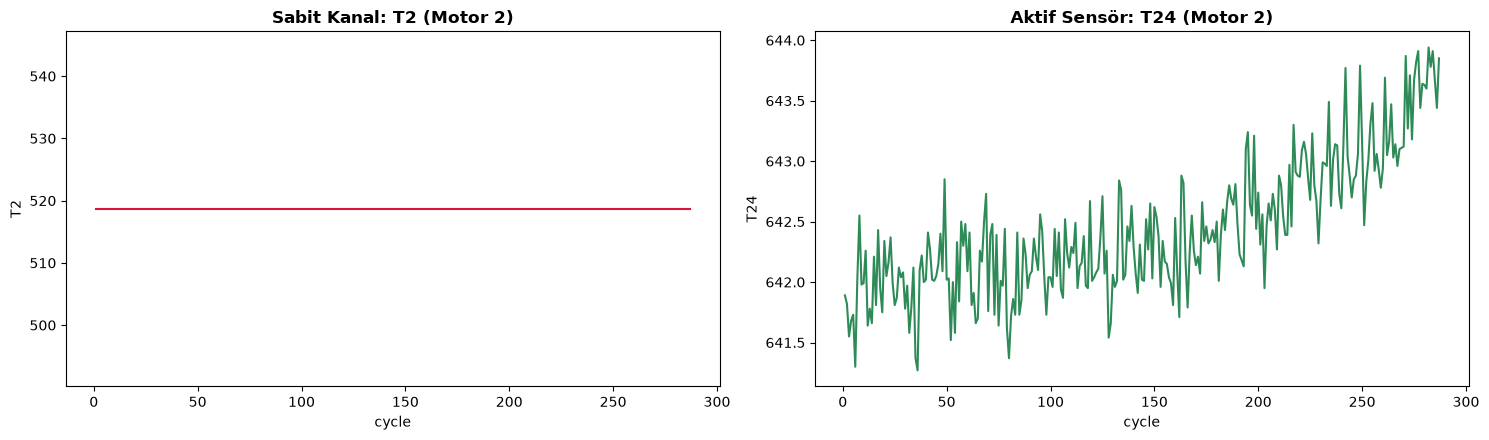

In [1]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

index_cols = ["unit", "cycle"]
op_cols = ["op_set1", "op_set2", "op_set3"]
sensor_cols = [
    "T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc",
    "epr", "Ps30", "phi", "NRf", "NRc", "BPR", "farB", "htBleed",
    "Nf_dmd", "PCNfR_dmd", "W31", "W32",
]
all_cols = index_cols + op_cols + sensor_cols

data_dir = next(
    (p for p in [Path("data"), Path("../data")]
     if (p / "train_FD001.txt").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        f"train_FD001.txt bulunamadı. Mevcut dizin: {Path.cwd()}"
    )

train_df = pd.read_csv(
    data_dir / "train_FD001.txt",
    sep=r"\s+", header=None, names=all_cols
)
test_df = pd.read_csv(
    data_dir / "test_FD001.txt",
    sep=r"\s+", header=None, names=all_cols
)

# 1) Eksik ve mükerrer kayıt kontrolü
print("Train eksik değer sayısı:", int(train_df.isna().sum().sum()))
print("Test eksik değer sayısı :", int(test_df.isna().sum().sum()))

print(
    "Train mükerrer (unit, cycle):",
    int(train_df.duplicated(subset=["unit", "cycle"]).sum()),
)
print(
    "Test mükerrer (unit, cycle):",
    int(test_df.duplicated(subset=["unit", "cycle"]).sum()),
)

# 2) Train / Validation ayrımı: motor (unit) bazında
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(train_df, groups=train_df["unit"])
)

train_raw = train_df.iloc[train_idx].copy()
val_raw = train_df.iloc[val_idx].copy()

assert set(train_raw["unit"]).isdisjoint(set(val_raw["unit"]))

print("\n=== TRAIN / VALIDATION AYRIMI ===")
print("Train motor sayısı:", train_raw["unit"].nunique())
print("Validation motor sayısı:", val_raw["unit"].nunique())
print("Train satır sayısı:", len(train_raw))
print("Validation satır sayısı:", len(val_raw))

# 3) Sabit sütunları yalnızca TRAIN üzerinden belirle
constant_cols = [
    col for col in train_raw.columns
    if col not in ["unit", "cycle"] and train_raw[col].nunique() <= 1
]

train_clean = train_raw.drop(columns=constant_cols).copy()
val_clean = val_raw.drop(columns=constant_cols).copy()
test_clean = test_df.drop(columns=constant_cols).copy()

print("\nÇıkarılan sabit sütunlar:", constant_cols)
print("Çıkarılan sütun sayısı:", len(constant_cols))
print("train_clean şekli:", train_clean.shape)
print("val_clean şekli:", val_clean.shape)
print("test_clean şekli:", test_clean.shape)

# 4) Örnek motor için sabit ve aktif sensör karşılaştırması
sample_unit = train_raw["unit"].iloc[0]
unit_df = train_raw[train_raw["unit"] == sample_unit]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

sns.lineplot(data=unit_df, x="cycle", y="T2", ax=ax[0], color="crimson")
ax[0].set_title(f"Sabit Kanal: T2 (Motor {sample_unit})", fontweight="bold")

sns.lineplot(data=unit_df, x="cycle", y="T24", ax=ax[1], color="seagreen")
ax[1].set_title(f"Aktif Sensör: T24 (Motor {sample_unit})", fontweight="bold")

plt.tight_layout()
plt.show()


### Hedef Değişkenlerin Oluşturulması (`RUL_linear` ve `RUL_capped125`)
Eğitim setindeki her motor (`unit`) arıza döngüsüne kadar çalıştığından, kalan kullanım ömrü (`RUL_linear = max_cycle - cycle`) doğrudan hesaplanabilmektedir. Erken sağlıklı döngülerdeki yatay davranışı dengelemek ve bozulmaya yakın kritik döneme odaklanmak amacıyla `125` döngü üst sınırlı `RUL_capped125` hedefi de eklenmektedir. Test setinde gerçek RUL değerleri ayrı dosyada tutulduğundan bu adım yalnızca eğitim setine uygulanmaktadır.

In [2]:

RUL_CAP = 125

def add_rul_targets(df):
    df = df.copy()

    max_cycle = df.groupby("unit")["cycle"].transform("max")
    df["RUL_linear"] = max_cycle - df["cycle"]
    df["RUL_capped125"] = df["RUL_linear"].clip(upper=RUL_CAP)

    return df


train_clean = add_rul_targets(train_clean)
val_clean = add_rul_targets(val_clean)

print("TRAIN RUL örneği:")
print(train_clean[["unit", "cycle", "RUL_linear", "RUL_capped125"]].head(10))

print("\nVALIDATION RUL örneği:")
print(val_clean[["unit", "cycle", "RUL_linear", "RUL_capped125"]].head(10))

print("\nTrain RUL istatistikleri:")
print(train_clean["RUL_capped125"].describe().round(2))

print("\nValidation RUL istatistikleri:")
print(val_clean["RUL_capped125"].describe().round(2))


TRAIN RUL örneği:
     unit  cycle  RUL_linear  RUL_capped125
192     2      1         286            125
193     2      2         285            125
194     2      3         284            125
195     2      4         283            125
196     2      5         282            125
197     2      6         281            125
198     2      7         280            125
199     2      8         279            125
200     2      9         278            125
201     2     10         277            125

VALIDATION RUL örneği:
   unit  cycle  RUL_linear  RUL_capped125
0     1      1         191            125
1     1      2         190            125
2     1      3         189            125
3     1      4         188            125
4     1      5         187            125
5     1      6         186            125
6     1      7         185            125
7     1      8         184            125
8     1      9         183            125
9     1     10         182            125

Train RUL i

In [3]:
print("=== TEMİZLENMİŞ EĞİTİM VERİ SETİ ===")
train_clean.info()

print("\n=== TEMİZLENMİŞ VALIDATION VERİ SETİ ===")
val_clean.info()

=== TEMİZLENMİŞ EĞİTİM VERİ SETİ ===
<class 'pandas.DataFrame'>
Index: 16561 entries, 192 to 20630
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   unit           16561 non-null  int64  
 1   cycle          16561 non-null  int64  
 2   op_set1        16561 non-null  float64
 3   op_set2        16561 non-null  float64
 4   T24            16561 non-null  float64
 5   T30            16561 non-null  float64
 6   T50            16561 non-null  float64
 7   P15            16561 non-null  float64
 8   P30            16561 non-null  float64
 9   Nf             16561 non-null  float64
 10  Nc             16561 non-null  float64
 11  Ps30           16561 non-null  float64
 12  phi            16561 non-null  float64
 13  NRf            16561 non-null  float64
 14  NRc            16561 non-null  float64
 15  BPR            16561 non-null  float64
 16  htBleed        16561 non-null  int64  
 17  W31            16561 non-nu

## 2.2 Zaman Serisi Özellik Mühendisliği (Feature Engineering)

Bu adımda doğrudan temizlenmiş eğitim (`train_clean`) ve test (`test_clean`) veri setlerindeki aktif çalışma ve sensör kanalları üzerinden motor (`unit`) bazlı zamansal özellikler türetilmektedir. Her motorun kendi döngü (`cycle`) sırası korunarak hesaplama yapılmakta; böylece motor geçişlerinde bir ünitenin son döngüsünün diğer ünitenin ilk döngüsüne karışması ve hedef değişken (`RUL_linear`, `RUL_capped125`) üzerinden özellik türetilerek veri sızıntısı oluşması engellenmektedir.

### Türetilen Özellikler (`window = 10`)
Aktif özellik sütunlarının her biri için aşağıdaki üç zamansal öznitelik oluşturulmaktadır:
* **Kayan Ortalama (`{col}_roll_mean_10`):** Kısa vadeli ölçüm dalgalanmalarını yumuşatarak sensördeki kademeli bozulma eğilimini daha belirgin hale getirmek amacıyla (`min_periods=1`).
* **Kayan Standart Sapma (`{col}_roll_std_10`):** Pencere içindeki yerel oynaklığı ve sinyal kararsızlığını ölçmek amacıyla (`min_periods=1`, ilk adımdaki `NaN` değerler `0.0` ile doldurulmaktadır).
* **Ardışık Fark (`{col}_diff`):** Ardışık döngüler arasındaki değişim miktarını ve bozulma hızını yakalamak amacıyla (`fillna(0.0)`).

In [4]:

import numpy as np
import pandas as pd

exclude_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}

base_feature_cols = [
    col for col in train_clean.columns
    if col not in exclude_cols
]

window = 10


def add_temporal_features(
    df: pd.DataFrame,
    feature_cols: list[str],
    win: int = 10
) -> pd.DataFrame:

    out_parts = []

    for _, grp in df.groupby("unit", sort=True):
        sub = grp.sort_values("cycle").copy()
        new_cols = {}

        for col in feature_cols:
            s = sub[col].astype(float)

            new_cols[f"{col}_roll_mean_{win}"] = (
                s.rolling(window=win, min_periods=1).mean()
            )

            new_cols[f"{col}_roll_std_{win}"] = (
                s.rolling(window=win, min_periods=1).std().fillna(0.0)
            )

            new_cols[f"{col}_diff"] = s.diff().fillna(0.0)

        sub = pd.concat(
            [sub, pd.DataFrame(new_cols, index=sub.index)],
            axis=1
        )

        out_parts.append(sub)

    return pd.concat(out_parts, ignore_index=True)


# Üç veri setine de aynı Feature Engineering uygulanıyor
train_fe = add_temporal_features(
    train_clean, base_feature_cols, win=window
)

val_fe = add_temporal_features(
    val_clean, base_feature_cols, win=window
)

test_fe = add_temporal_features(
    test_clean, base_feature_cols, win=window
)


print("Temel özellik sayısı:", len(base_feature_cols))
print("train_fe şekli:", train_fe.shape)
print("val_fe şekli:", val_fe.shape)
print("test_fe şekli:", test_fe.shape)

print("\nTrain NaN:", int(train_fe.isna().sum().sum()))
print("Validation NaN:", int(val_fe.isna().sum().sum()))
print("Test NaN:", int(test_fe.isna().sum().sum()))

print(
    "\nTrain inf:",
    int(np.isinf(train_fe.select_dtypes(include=np.number)).sum().sum())
)
print(
    "Validation inf:",
    int(np.isinf(val_fe.select_dtypes(include=np.number)).sum().sum())
)
print(
    "Test inf:",
    int(np.isinf(test_fe.select_dtypes(include=np.number)).sum().sum())
)


Temel özellik sayısı: 17
train_fe şekli: (16561, 72)
val_fe şekli: (4070, 72)
test_fe şekli: (13096, 70)

Train NaN: 0
Validation NaN: 0
Test NaN: 0

Train inf: 0
Validation inf: 0
Test inf: 0


### Türetilen Özelliklerin Tablo ve Grafik ile İncelenmesi (`unit = 1`)

Üretilen zamansal özelliklerin (`roll_mean_10`, `roll_std_10`, `diff`) motor bazında ve döngü sırasına göre doğru hesaplandığını somut olarak doğrulamak amacıyla örnek bir motor (`target_unit = 14`) ve seçili bir sensör (`sensor = "T24"`) üzerinden ilk döngülerin tablosu ile tüm ömür boyunca davranış grafiği incelenmektedir. Farklı bir motor veya sensör incelemek için `target_unit` ve `sensor` değişkenlerini değiştirmek yeterlidir.

,unit,cycle,T24,T24_roll_mean_10,T24_roll_std_10,T24_diff
0,2,1,641.89,641.890,0.000,0.00
1,2,2,641.82,641.855,0.049,-0.07
2,2,3,641.55,641.753,0.180,-0.27
3,2,4,641.68,641.735,0.151,0.13
4,2,5,641.73,641.734,0.131,0.05
5,2,6,641.30,641.662,0.212,-0.43
6,2,7,642.03,641.714,0.239,0.73
7,2,8,642.55,641.819,0.369,0.52
8,2,9,641.98,641.837,0.349,-0.57
9,2,10,641.99,641.852,0.333,0.01


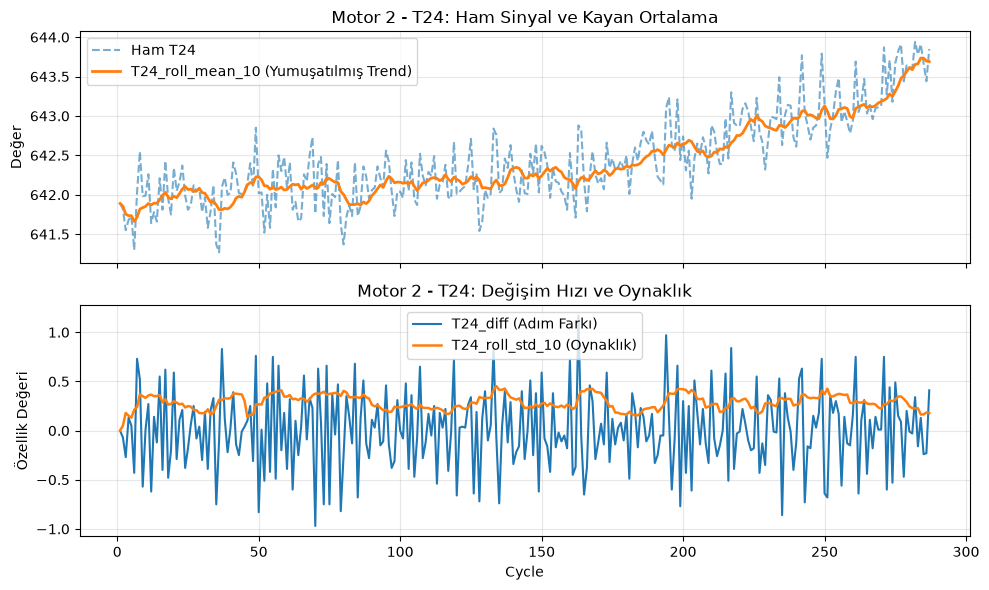

In [5]:
import matplotlib.pyplot as plt

# İncelemek istediğin motor ve sensörü buradan kolayca değiştirebilirsin
target_unit = train_raw["unit"].iloc[0]
sensor = "T24"

cols_to_show = [
    "unit",
    "cycle",
    sensor,
    f"{sensor}_roll_mean_10",
    f"{sensor}_roll_std_10",
    f"{sensor}_diff",
]

# 1. İlk 12 döngü için tablo görünümü
sample_table = (
    train_fe[train_fe["unit"] == target_unit]
    .sort_values("cycle")[cols_to_show]
    .head(12)
    .round(3)
)
display(sample_table)  # Düz Python betiğinde çalışıyorsan print(sample_table) kullanabilirsin

# 2. Tüm döngüler boyunca görsel karşılaştırma
u_df = train_fe[train_fe["unit"] == target_unit].sort_values("cycle")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(
    u_df["cycle"],
    u_df[sensor],
    label=f"Ham {sensor}",
    alpha=0.6,
    linestyle="--",
)
axes[0].plot(
    u_df["cycle"],
    u_df[f"{sensor}_roll_mean_10"],
    label=f"{sensor}_roll_mean_10 (Yumuşatılmış Trend)",
    linewidth=2,
)
axes[0].set_title(f"Motor {target_unit} - {sensor}: Ham Sinyal ve Kayan Ortalama")
axes[0].set_ylabel("Değer")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    u_df["cycle"],
    u_df[f"{sensor}_diff"],
    label=f"{sensor}_diff (Adım Farkı)",
)
axes[1].plot(
    u_df["cycle"],
    u_df[f"{sensor}_roll_std_10"],
    label=f"{sensor}_roll_std_10 (Oynaklık)",
    linewidth=1.8,
)
axes[1].set_title(f"Motor {target_unit} - {sensor}: Değişim Hızı ve Oynaklık")
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel("Özellik Değeri")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.3 Normalizasyon ve Standardizasyon (Ölçekleme)

Özellik mühendisliği adımı sonucunda elde edilen 17 temel kanal ve 51 türetilmiş zaman serisi özelliği olmak üzere toplam 68 öznitelik birbirinden farklı fiziksel birimlere ve sayısal genliklere sahiptir. Farklı ölçeklerdeki değişkenlerin bir arada bulunması; özellikle gradyan tabanlı, mesafe/kernel kullanan veya düzenlileştirme (*regularization*) uygulanan modellerde büyük genlikli sütunların öğrenme sürecini baskılamasına yol açabilmektedir. Bu nedenle `unit`, `cycle` ve hedef değişkenler (`RUL_linear`, `RUL_capped125`) ölçekleme kapsamı dışında bırakılarak yalnızca 68 girdi özelliği için ölçekleme yapısı tanımlanmıştır.

Bu çalışmada sütunların dağılım ve oynaklık davranışına göre iki farklı ölçekleyici birlikte yapılandırılmıştır (`ColumnTransformer`):
* **Standardizasyon (`StandardScaler`):** Temel aktif kanallar ile kayan ortalama (`roll_mean_10`) sütunlarında dağılım yapısını bozmadan ortalama ~0 ve standart sapma 1 olacak şekilde Z-skor dönüşümü planlanmıştır.
* **Dayanıklı Ölçekleme (`RobustScaler`):** Ardışık fark (`diff`) ve kayan standart sapma (`roll_std_10`) gibi anlık değişim ve yerel oynaklık barındıran sütunlarda ise medyan ve çeyrekler açıklığı (`IQR = Q3 - Q1`) esas alınarak ani dalgalanmaların ölçekleme katsayılarını bozması engellenmiştir.

Veri sızıntısını (*data leakage*) önlemek ve henüz tamamlanmamış olan özellik seçimi ile modelleme adımlarını etkilememek amacıyla ölçekleyici parametreleri yalnızca eğitim seti (`train_fe`) üzerinde öğrenilmiş (`fit`), test setine (`test_fe`) ise bu aşamada dönüşüm (`transform`) uygulanmamıştır. Nihai dönüşüm işlemi özellik seçimi tamamlandıktan sonra model eğitim hattı (*pipeline*) içerisinde uygulanmak üzere hazırlanmış; eğitim seti önizlemesi üzerinden eksik/sonsuz değer bulunmadığı ve dağılımların beklenen şekilde merkezileştiği doğrulanmıştır.

Train / Validation / Test özellikleri uyumlu.
Özellik sütunu sayısı: 68

=== ÖLÇEKLEME KONTROLLERİ ===
Toplam ölçeklenecek özellik sayısı: 68
StandardScaler sütun sayısı: 34
RobustScaler sütun sayısı: 34
Train şekli: (16561, 72)
Validation şekli: (4070, 72)
Test şekli: (13096, 70)
Train ölçekleme önizlemesi NaN: 0
Train ölçekleme önizlemesi inf: 0

[T30] Ölçekleme öncesi:
           T30  T30_roll_mean_10  T30_roll_std_10  T30_diff
mean  1590.489          1590.160            3.859     0.079
std      6.085             4.510            1.001     5.608
min   1571.040          1573.020            0.000   -23.480
max   1616.910          1605.578           12.445    23.120

[T30] Ölçekleme sonrası:
        T30  T30_roll_mean_10  T30_roll_std_10  T30_diff
mean -0.000            -0.000            0.018     0.003
std   1.000             1.000            0.782     0.744
min  -3.196            -3.800           -2.996    -3.122
max   4.342             3.419            6.726     3.058


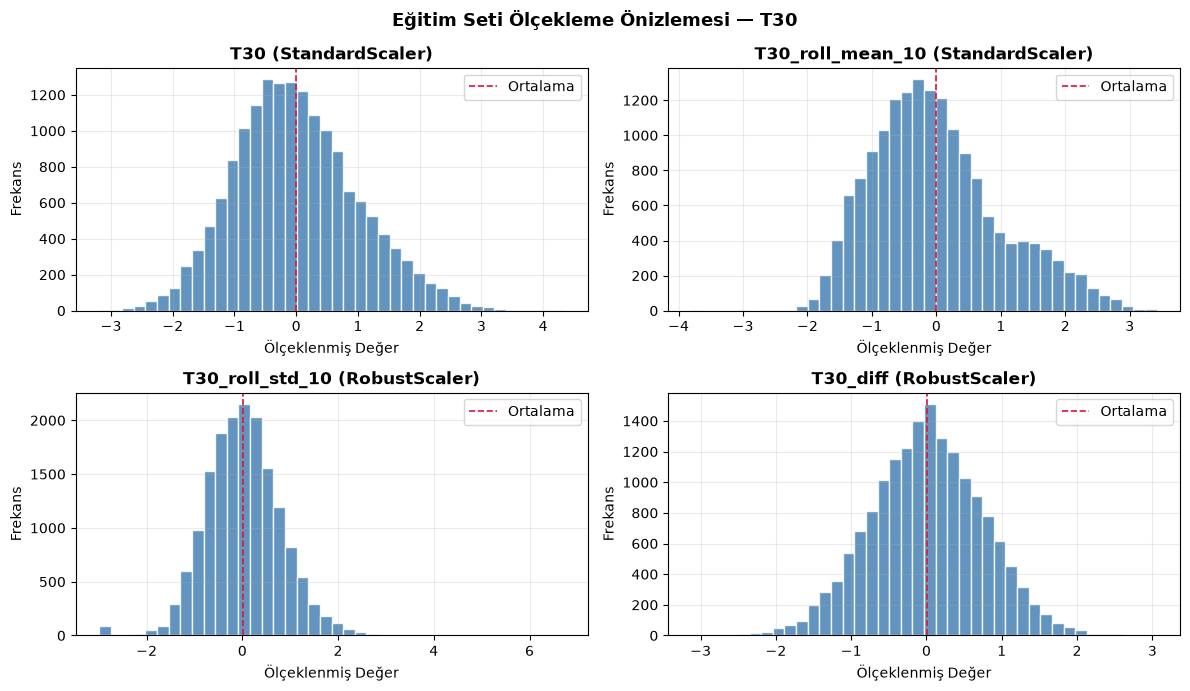

In [6]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, StandardScaler

# İncelemek istediğin sensör
sensor = "T30"

# 1) Ölçeklenecek özellik sütunları
excluded_cols = {"unit", "cycle", "RUL_linear", "RUL_capped125"}

feature_cols = [
    col for col in train_fe.columns
    if col not in excluded_cols
]

# 2) Train / Validation / Test özellik uyumluluğu kontrolleri
val_feature_cols = [
    col for col in val_fe.columns
    if col not in excluded_cols
]

test_feature_cols = [
    col for col in test_fe.columns
    if col not in excluded_cols
]

assert feature_cols == val_feature_cols, (
    "Train ve Validation özellik sütunları aynı değil!"
)

assert feature_cols == test_feature_cols, (
    "Train ve Test özellik sütunları aynı değil!"
)

print("Train / Validation / Test özellikleri uyumlu.")
print("Özellik sütunu sayısı:", len(feature_cols))

# 3) Diff ve rolling std için RobustScaler
robust_cols = [
    col for col in feature_cols
    if col.endswith("_diff") or "_roll_std_" in col
]

standard_cols = [
    col for col in feature_cols
    if col not in robust_cols
]

preprocessor = ColumnTransformer(
    transformers=[
        ("std", StandardScaler(), standard_cols),
        ("rob", RobustScaler(), robust_cols),
    ],
    remainder="drop",
)

# 4) SADECE train üzerinde fit ve transform
X_train_preview_arr = preprocessor.fit_transform(
    train_fe[feature_cols]
)

scaled_col_names = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

# Orijinal train_fe korunur
train_scaled_preview = train_fe.copy()

train_scaled_preview[scaled_col_names] = pd.DataFrame(
    X_train_preview_arr,
    columns=scaled_col_names,
    index=train_scaled_preview.index,
)

train_scaled_preview = train_scaled_preview[train_fe.columns]

# 5) Bütünlük kontrolleri
print("\n=== ÖLÇEKLEME KONTROLLERİ ===")

print("Toplam ölçeklenecek özellik sayısı:", len(feature_cols))
print("StandardScaler sütun sayısı:", len(standard_cols))
print("RobustScaler sütun sayısı:", len(robust_cols))

print("Train şekli:", train_fe.shape)
print("Validation şekli:", val_fe.shape)
print("Test şekli:", test_fe.shape)

print(
    "Train ölçekleme önizlemesi NaN:",
    int(train_scaled_preview[feature_cols].isna().sum().sum())
)

print(
    "Train ölçekleme önizlemesi inf:",
    int(np.isinf(
        train_scaled_preview[feature_cols].select_dtypes(include=np.number)
    ).sum().sum())
)

# 6) Sensör ve türevlerini karşılaştır
check_cols = [
    sensor,
    f"{sensor}_roll_mean_10",
    f"{sensor}_roll_std_10",
    f"{sensor}_diff",
]

# Kontrol edilecek sütunların mevcut olduğunu doğrula
missing_check_cols = [
    col for col in check_cols
    if col not in train_scaled_preview.columns
]

if missing_check_cols:
    raise ValueError(
        f"Kontrol sütunları bulunamadı: {missing_check_cols}"
    )

print(f"\n[{sensor}] Ölçekleme öncesi:")
print(
    train_fe[check_cols]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

print(f"\n[{sensor}] Ölçekleme sonrası:")
print(
    train_scaled_preview[check_cols]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

# 7) Dağılım grafikleri
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.ravel()

for idx, col in enumerate(check_cols):

    scaler_tag = (
        "RobustScaler"
        if col in robust_cols
        else "StandardScaler"
    )

    axes[idx].hist(
        train_scaled_preview[col],
        bins=40,
        color="steelblue",
        edgecolor="white",
        alpha=0.85,
    )

    axes[idx].axvline(
        train_scaled_preview[col].mean(),
        color="crimson",
        linestyle="--",
        linewidth=1.2,
        label="Ortalama",
    )

    axes[idx].set_title(
        f"{col} ({scaler_tag})",
        fontweight="bold",
    )

    axes[idx].set_xlabel("Ölçeklenmiş Değer")
    axes[idx].set_ylabel("Frekans")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.25)

plt.suptitle(
    f"Eğitim Seti Ölçekleme Önizlemesi — {sensor}",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
plt.show()


### 2.4 Özellik Seçimi ve Önemi (Feature Selection / Importance)

Özellik mühendisliği adımı sonrasında elde edilen 68 girdi özelliğinin `RUL_capped125` hedef değişkeni üzerindeki bilgilendiriciliğini değerlendirmek ve ileride kurulacak tüm modellere uygun, sadeleştirilmiş bir öznitelik kümesi oluşturmak amacıyla modele bağımsız (*model-agnostic*) özellik seçimi uygulanmıştır.

Uygulanan seçim sürecinde ilk olarak varyansı `0.0001` eşiğinin altında kalan 15 özellik (`op_set1`, `op_set2` ve `P15` kanalları ile bunların türevleri ve `Nf_roll_std_10`, `NRf_roll_std_10`, `BPR_roll_std_10`) elenmiştir. Kalan özellikler için `RUL_capped125` ile doğrusal ve doğrusal olmayan ilişkileri ölçmek amacıyla Karşılıklı Bilgi (*Mutual Information*) skorları hesaplanmış ve yüksek Mutual Information skoruna sahip `roll_mean_10` türevlerinin (özellikle `T50_roll_mean_10`, `W32_roll_mean_10`, `Ps30_roll_mean_10` ve `htBleed_roll_mean_10`) motor bozunma sürecini temsil etmede öne çıktığı gözlemlenmiştir[cite: 5]. Aynı kök kanala ait özellikler arasında `0.98` üzerindeki yüksek korelasyonlarda ise Mutual Information skoru daha düşük olan `Nc` (`0.2231 <= 0.2821`) ve `NRc` (`0.2231 <= 0.2868`) sütunları ayıklanırken, farklı sensör kanalları arasındaki korelasyonlar fiziksel bilgi kaybı yaşanmaması adına silinmeden incelenmiş; böylece 68 aday özellikten 51 öznitelik (`selected_features`) seçilerek modelleme aşamasına aktarılmıştır.

Train motor sayısı: 80
Validation motor sayısı: 20

=== FEATURE SELECTION SONUÇLARI ===
Train motor sayısı: 80
Validation motor sayısı: 20
Başlangıç aday özellik: 68
Low variance elenen (<0.0001): 15
Kanal içi >0.98 elenen: 2
Seçilen özellik sayısı: 51

Düşük varyanslı sütunlar:
['op_set1', 'op_set2', 'P15', 'op_set1_roll_mean_10', 'op_set1_roll_std_10', 'op_set1_diff', 'op_set2_roll_mean_10', 'op_set2_roll_std_10', 'op_set2_diff', 'P15_roll_mean_10', 'P15_roll_std_10', 'P15_diff', 'Nf_roll_std_10', 'NRf_roll_std_10', 'BPR_roll_std_10']

Kanal içi tekrar nedeniyle elenen özellikler:
 - Nc: Nc_roll_mean_10 ile r=0.9840 (MI: 0.2231 <= 0.2821)
 - NRc: NRc_roll_mean_10 ile r=0.9873 (MI: 0.2231 <= 0.2868)

Farklı kanallar arası yüksek korelasyon (>0.9, silinmedi): 61
 - Nc_roll_mean_10 <-> NRc_roll_mean_10: |r| = 0.9882
 - NRc <-> Nc_roll_mean_10: |r| = 0.9777
 - Ps30_roll_mean_10 <-> phi_roll_mean_10: |r| = 0.9759
 - T50_roll_mean_10 <-> Ps30_roll_mean_10: |r| = 0.9749
 - Nf_roll_mean_10 <

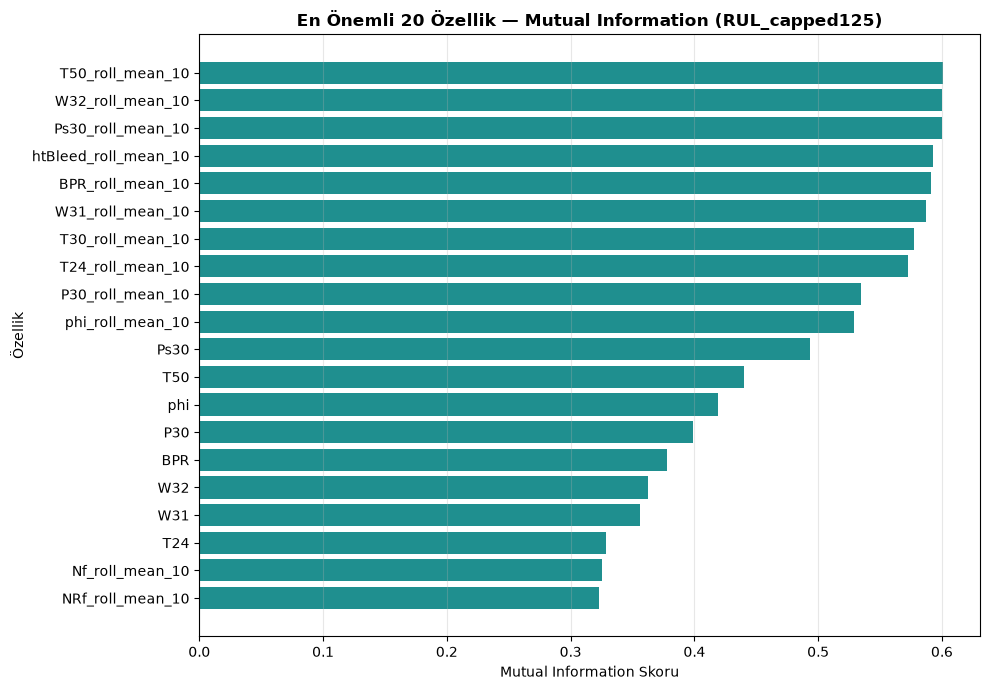

In [7]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression

# --- 0) Önceki FS ara değişkenlerini temizle ---
for _v in [
    "fs_df",
    "selected_features",
    "dropped_redundant",
    "low_var_cols",
    "vt",
    "mi_scores",
    "corr_matrix",
]:
    if _v in globals():
        del globals()[_v]


# --- Ayarlanabilir parametreler ---
TARGET_COL = "RUL_capped125"

VAR_THRESHOLD = 1e-4
SAME_CHANNEL_CORR_THRESHOLD = 0.98
CROSS_CHANNEL_INSPECT_THRESHOLD = 0.90

TOP_N_PLOT = 20
RANDOM_STATE = 42


def get_base_channel(col_name: str) -> str:
    """Özellik adından kök sensör/operasyonel kanal adını çıkarır."""

    for suffix in ["_roll_mean_10", "_roll_std_10", "_diff"]:
        if col_name.endswith(suffix):
            return col_name[:-len(suffix)]

    return col_name


# --- 1) Önceden ayrılmış Train / Validation verilerini kullan ---

train_fs_split = train_fe.copy()
val_fs_split = val_fe.copy()

# Motorların birbirinden bağımsız olduğunu doğrula
assert set(train_fs_split["unit"]).isdisjoint(
    set(val_fs_split["unit"])
), "Veri sızıntısı: Aynı motor hem train hem validation setinde!"

print("Train motor sayısı:", train_fs_split["unit"].nunique())
print("Validation motor sayısı:", val_fs_split["unit"].nunique())


# --- 2) Model girdisi adaylarını belirle ---

excluded_cols = {
    "unit",
    "cycle",
    "RUL_linear",
    "RUL_capped125",
}

candidate_cols = [
    col for col in train_fs_split.columns
    if col not in excluded_cols
]

X_tr = train_fs_split[candidate_cols]
y_tr = train_fs_split[TARGET_COL]


# --- 3) Low Variance Filter (yalnızca train) ---

vt = VarianceThreshold(threshold=VAR_THRESHOLD)
vt.fit(X_tr)

var_mask = vt.get_support()

low_var_cols = [
    col for col, keep in zip(candidate_cols, var_mask)
    if not keep
]

active_cols = [
    col for col, keep in zip(candidate_cols, var_mask)
    if keep
]

X_tr_active = X_tr[active_cols]


# --- 4) Mutual Information (yalnızca train) ---

mi_scores = mutual_info_regression(
    X_tr_active,
    y_tr,
    random_state=RANDOM_STATE,
)

fs_df = (
    pd.DataFrame({
        "feature": active_cols,
        "base_channel": [
            get_base_channel(c) for c in active_cols
        ],
        "mi_score": mi_scores,
    })
    .sort_values("mi_score", ascending=False)
    .reset_index(drop=True)
)


# --- 5) Aynı kanalda yüksek korelasyon varsa düşük MI olanı ele ---

corr_matrix = X_tr_active.corr().abs()

mi_lookup = dict(
    zip(fs_df["feature"], fs_df["mi_score"])
)

selected_features = []
dropped_redundant = []
drop_reasons = {}

for _, row in fs_df.iterrows():

    feat = row["feature"]
    feat_ch = row["base_channel"]
    feat_mi = row["mi_score"]

    conflicting_kept = [
        kept
        for kept in selected_features
        if (
            get_base_channel(kept) == feat_ch
            and corr_matrix.loc[feat, kept]
            > SAME_CHANNEL_CORR_THRESHOLD
        )
    ]

    if conflicting_kept:

        best_kept = max(
            conflicting_kept,
            key=lambda k: mi_lookup[k]
        )

        if feat_mi <= mi_lookup[best_kept]:

            dropped_redundant.append(feat)

            drop_reasons[feat] = (
                f"{best_kept} ile "
                f"r={corr_matrix.loc[feat, best_kept]:.4f} "
                f"(MI: {feat_mi:.4f} <= "
                f"{mi_lookup[best_kept]:.4f})"
            )

        else:

            selected_features.remove(best_kept)
            dropped_redundant.append(best_kept)

            drop_reasons[best_kept] = (
                f"{feat} ile "
                f"r={corr_matrix.loc[feat, best_kept]:.4f} "
                f"(MI: {mi_lookup[best_kept]:.4f} <= "
                f"{feat_mi:.4f})"
            )

            selected_features.append(feat)

    else:
        selected_features.append(feat)


fs_df["status"] = np.where(
    fs_df["feature"].isin(selected_features),
    "Seçildi",
    "Elenen (Kanal İçi Tekrar)",
)


# --- 6) Farklı kanallar arası yüksek korelasyonu raporla ---

cross_high_corr = []

cols_list = X_tr_active.columns.tolist()

for i in range(len(cols_list)):

    for j in range(i + 1, len(cols_list)):

        c1 = cols_list[i]
        c2 = cols_list[j]

        if get_base_channel(c1) != get_base_channel(c2):

            r_val = corr_matrix.loc[c1, c2]

            if r_val > CROSS_CHANNEL_INSPECT_THRESHOLD:

                cross_high_corr.append(
                    (c1, c2, round(float(r_val), 4))
                )

cross_high_corr.sort(
    key=lambda x: x[2],
    reverse=True
)


# --- 7) Özet çıktılar ---

print("\n=== FEATURE SELECTION SONUÇLARI ===")

print(
    f"Train motor sayısı: "
    f"{train_fs_split['unit'].nunique()}"
)

print(
    f"Validation motor sayısı: "
    f"{val_fs_split['unit'].nunique()}"
)

print("Başlangıç aday özellik:", len(candidate_cols))

print(
    f"Low variance elenen (<{VAR_THRESHOLD}): "
    f"{len(low_var_cols)}"
)

print(
    f"Kanal içi >{SAME_CHANNEL_CORR_THRESHOLD} elenen: "
    f"{len(dropped_redundant)}"
)

print("Seçilen özellik sayısı:", len(selected_features))


if low_var_cols:

    print("\nDüşük varyanslı sütunlar:")
    print(low_var_cols)


if dropped_redundant:

    print("\nKanal içi tekrar nedeniyle elenen özellikler:")

    for k, v in drop_reasons.items():
        print(f" - {k}: {v}")


print(
    f"\nFarklı kanallar arası yüksek korelasyon "
    f"(>{CROSS_CHANNEL_INSPECT_THRESHOLD}, silinmedi): "
    f"{len(cross_high_corr)}"
)

for c1, c2, r_val in cross_high_corr[:10]:

    print(f" - {c1} <-> {c2}: |r| = {r_val}")


print("\nEn önemli ilk 15 özellik:")

print(
    fs_df[
        ["feature", "base_channel", "mi_score", "status"]
    ]
    .head(15)
    .round(4)
    .to_string(index=False)
)


# --- 8) Görselleştirme ---

top_plot_df = fs_df.head(TOP_N_PLOT).iloc[::-1]

bar_colors = [
    "teal" if st == "Seçildi" else "coral"
    for st in top_plot_df["status"]
]

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_plot_df["feature"],
    top_plot_df["mi_score"],
    color=bar_colors,
    alpha=0.88,
)

ax.set_title(
    f"En Önemli {TOP_N_PLOT} Özellik — "
    f"Mutual Information ({TARGET_COL})",
    fontweight="bold",
)

ax.set_xlabel("Mutual Information Skoru")
ax.set_ylabel("Özellik")
ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
from datetime import datetime, timezone
import json
from pathlib import Path

# Notebook'un çalışma dizinine göre proje kökünü bul (notebooks/ altındaysa bir üst dizine çıkar)
base_dir = Path.cwd()
if (base_dir / "notebooks").exists():
  project_root = base_dir
elif base_dir.name == "notebooks" and (base_dir.parent / "data").exists():
  project_root = base_dir.parent
else:
  project_root = base_dir

artifacts_dir = project_root / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1) Zaman serisi özellikleri eklenmiş veri setlerini kaydet
train_fe.to_csv(artifacts_dir / "train_fe.csv", index=False)
test_fe.to_csv(artifacts_dir / "test_fe.csv", index=False)

# İstersen parquet de kaydedebilirsin (ortamda pyarrow kuruluysa):
# train_fe.to_parquet(artifacts_dir / "train_fe.parquet", index=False)
# test_fe.to_parquet(artifacts_dir / "test_fe.parquet", index=False)

# 2) Seçili özellikleri ve özet metadata'yı JSON olarak kaydet
if "selected_features" not in globals():
  raise NameError(
      "selected_features bulunamadı. Önce feature selection hücresini"
      " çalıştır."
  )

metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "target_column": "RUL_capped125",
    "num_selected_features": len(selected_features),
    "selected_features": list(selected_features),
}

with open(
    artifacts_dir / "selected_features.json", "w", encoding="utf-8"
) as f:
  json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Kaydedilen klasör:", artifacts_dir)
print("  - train_fe.csv")
print("  - test_fe.csv")
print("  - selected_features.json")

Kaydedilen klasör: d:\Projects\turbofan-predictive-maintenance\artifacts
  - train_fe.csv
  - test_fe.csv
  - selected_features.json
